# Lab 4

Finish a function in `lab4.py`, then run its cell. Last week's searches were blind: they recognised a goal when they stumbled on one. This week the frontier is ordered by an estimate of how far the goal is.

In [4]:
# %load_ext autoreload
# %autoreload 2
import time
from lab2.lab2 import load, successors, goal_reached, parse_problem, ground
from lab3.lab3 import bfs, dfs, ucs, plan_cost
from lab4.lab4 import iterative_deepening, relaxed_costs, goal_count, h_add, greedy
from viz import explore, draw_search, workshop_problem

## Warm-up: iterative deepening

Wednesday's lecture: depth-first search with a limit of 0, then 1, then 2, ... Breadth-first's guarantee with depth-first's memory, paid for by redoing the shallow levels.

In [2]:


for dom, prob in [("vacuum-domain.pddl", "vacuum-tiny.pddl"), ("blocks-domain.pddl", "blocks-sussman.pddl"), ("domain.pddl", "problem.pddl")]:
    d, p, acts = load(dom, prob)
    print(f"{p.name:12s} bfs: {bfs(p, acts)}")
    print(f"{'':12s} ids: {iterative_deepening(p, acts)}")

tiny         bfs: 5 actions, cost 5 | 13 expanded, frontier up to 4
             ids: 5 actions, cost 5 | 46 expanded, frontier up to 4
sussman      bfs: 6 actions, cost 9 | 18 expanded, frontier up to 5
             ids: 6 actions, cost 9 | 61 expanded, frontier up to 4
two-animals  bfs: 9 actions, cost 14 | 564 expanded, frontier up to 252
             ids: 9 actions, cost 12 | 1739 expanded, frontier up to 21


Same plan length every time; three to four times the expansions; a frontier of 21 states instead of 252 on the two animals. Expansions are time, the frontier is memory, and memory is what runs out first.

## A sense of direction

Two estimates of the distance to the goal, both computed from the problem itself. `goal_count` counts the goal facts that are still false. `relaxed_costs` pretends nothing is ever deleted and asks how cheaply each fact could become true; `h_add` sums that over the goal facts.

In [3]:
domain, problem, actions = load("domain.pddl", "problem.pddl")
costs = relaxed_costs(problem.init, actions)
for f in sorted(problem.goal):
    print(f"{str(f):30s} relaxed cost {costs[f]}")
print("goal_count", goal_count(problem.init, problem.goal, actions), "  h_add", h_add(problem.init, problem.goal, actions), "  true cost", ucs(problem, actions).cost)

('at', 'dog', 'outdoors')      relaxed cost 5
('cut-into-pieces', 'dog')     relaxed cost 3
('photo-taken', 'cat')         relaxed cost 2
goal_count 3   h_add 10   true cost 12


Three goal facts; relaxed costs 2, 3 and 5, so `h_add` says 10 where the truth is 12. Not bad for a world where nothing is ever put down. Now use it to order a frontier.

## Greedy best-first search: smallest h first

In [5]:
d, p4, acts4 = load("domain.pddl", "p4.pddl")
print("bfs, from Lab 3:       80,427 expanded")
print("greedy, goal_count:   ", greedy(p4, acts4, goal_count))
print("greedy, h_add:        ", greedy(p4, acts4, h_add))

bfs, from Lab 3:       80,427 expanded


TypeError: '>' not supported between instances of 'list' and 'int'

Four items. Breadth-first paid for 80,427 states; greedy with the crudest estimate paid for 40, and with `h_add` for 14. The plan is the same twelve actions. Look at what greedy expands on the blocks:

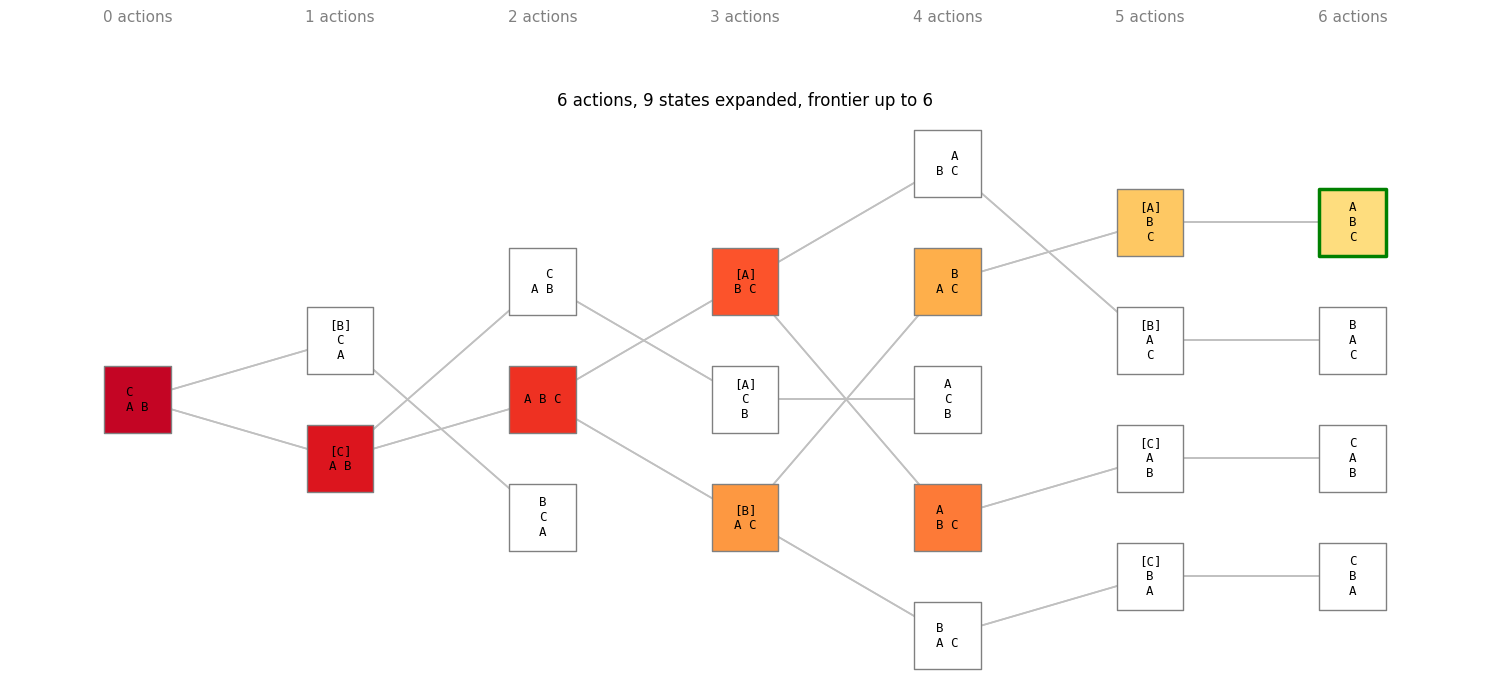

In [7]:
d, pb, actsb = load("blocks-domain.pddl", "blocks-sussman.pddl")
G = explore(pb.init, actsb)
draw_search(greedy(pb, actsb, h_add), G, pb.init, pb.goal, "blocks")

Dark to light is the order of expansion; white states were never expanded. Last week breadth-first coloured every column up to the goal. Greedy coloured a path.

## A*: smallest g + h first

Greedy ignores what a path has already cost. A* adds it back: the priority is the cost so far plus the estimate of what is left.

In [9]:
d, p3, acts3 = load("domain.pddl", "p3.pddl")
print("ucs:          ", ucs(p3, acts3))
print("A*, h_add:    ", astar(p3, acts3, h_add))
print("greedy, h_add:", greedy(p3, acts3, h_add))

ucs:           11 actions, cost 15 | 6989 expanded, frontier up to 3587
A*, h_add:     11 actions, cost 15 | 18 expanded, frontier up to 44
greedy, h_add: 11 actions, cost 15 | 13 expanded, frontier up to 31


Uniform-cost and A* both return cost 15; A* needed a small fraction of the expansions. Greedy returned a plan too, with no promise about its cost. A* keeps uniform-cost's guarantee only when the estimate never overestimates the truth. Does `h_add` never overestimate? The relaxed costs above added up to 10 against a truth of 12, so not here; but somewhere? That question is the coursework's, and you will answer it with code.

## Where blind search stopped

In [12]:
d, p6, acts6 = load("domain.pddl", "p6.pddl")
print("bfs, from Lab 3:   no plan after 400,000 expansions")
print("greedy, goal_count:", greedy(p6, acts6, goal_count))
print("greedy, h_add:     ", greedy(p6, acts6, h_add))
d, p10, acts10 = load("domain.pddl", "p10.pddl")
t = time.time(); print("ten items, greedy: ", greedy(p10, acts10, goal_count), f"({time.time() - t:.2f}s)")

bfs, from Lab 3:   no plan after 400,000 expansions
greedy, goal_count: 16 actions, cost 24 | 79 expanded, frontier up to 183
greedy, h_add:      17 actions, cost 25 | 27 expanded, frontier up to 84
ten items, greedy:  21 actions, cost 35 | 144 expanded, frontier up to 512 (0.03s)


Six items was the wall last week; both estimates go through it in under a hundred expansions. Notice that the better estimate returned the dearer plan (cost 25 against 24): greedy promises a plan, not a cheap one. Ten items, 532 grounded actions and about 10$^{13}$ states: a plan in a hundredth of a second.

## The mirror of last week's last cell

In [13]:
for n in (1, 2, 3, 4, 5, 6):
    p = parse_problem(workshop_problem(n))
    acts = [g for a in domain.actions.values() for g in ground(a, p.objects, domain.types)]
    t = time.time(); r = greedy(p, acts, h_add)
    print(f"{n} items: {len(r.plan)} actions, {len(r.expanded):3d} expanded, frontier up to {r.max_frontier:3d}, {time.time() - t:.2f}s")

1 items: 9 actions,  10 expanded, frontier up to  12, 0.00s
2 items: 9 actions,  11 expanded, frontier up to  21, 0.01s
3 items: 9 actions,  11 expanded, frontier up to  30, 0.02s
4 items: 9 actions,  11 expanded, frontier up to  39, 0.04s
5 items: 9 actions,  11 expanded, frontier up to  48, 0.08s
6 items: 9 actions,  11 expanded, frontier up to  57, 0.10s


Last week breadth-first went from 98 expansions to 171,399 as the room grew. Greedy with `h_add` expands eleven states whether there is one item or six: the room got bigger and the search did not notice, because the estimate points at the goal.

Next week: when the estimate lies, and search without a frontier at all.